In [1]:
# Test Environment
import ee
import geemap
import pygadm
import geopandas as gpd
import geojson

In [2]:
# Connect to GEE
ee.Initialize(project="tutorial-geoscripting-paulian")

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


In [3]:
# Import image
s1_collection = ee.ImageCollection("COPERNICUS/S1_GRD")

In [4]:
# set our initial zoom position for Constanta, Romania
center_lat = 44.1092
center_lon = 28.7499
zoomlevel = 12

# The following line will initialize the map
Map = geemap.Map(center=[center_lat, center_lon], zoom=zoomlevel)

# The following line will actually call and show the map:
Map

Map(center=[44.1092, 28.7499], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topri…

In [36]:
# Small time interval to get 1 snapshot
from_date = '2019-10-01'
to_date = '2019-10-10'

# Constanța port plus the offshore anchorage zone
aoi = ee.Geometry.Rectangle([28.64, 44.08, 28.85, 44.18])

# Image filter
image = s1_collection\
            .filterBounds(aoi)\
            .filterDate(from_date,to_date)\
            .sort("system:time_start", True)\
            .first()

# VV Polarization
vizualisation_params = {
    'min': -30,
    'max': -5,
    'opacity':1,
    'bands':['VH']
}

# Add image to base map
Map.addLayer(ee_object = image.select('VH').clip(aoi),
             vis_params = vizualisation_params,
             name = "first image")

In [37]:
import numpy as np
import matplotlib.pyplot as plt

vh = geemap.ee_to_numpy(image.select('VH'), region=aoi, scale=10)
vh = vh[:, :, 0]             # drop the band dimension -> 2D array (rows, cols)

print(vh.shape)               # number of raster cells
print(np.nanmin(vh), np.nanmax(vh), np.nanmedian(vh))

(1148, 1705)
-63.09105451078274 23.58938838661846 -33.81696883665595


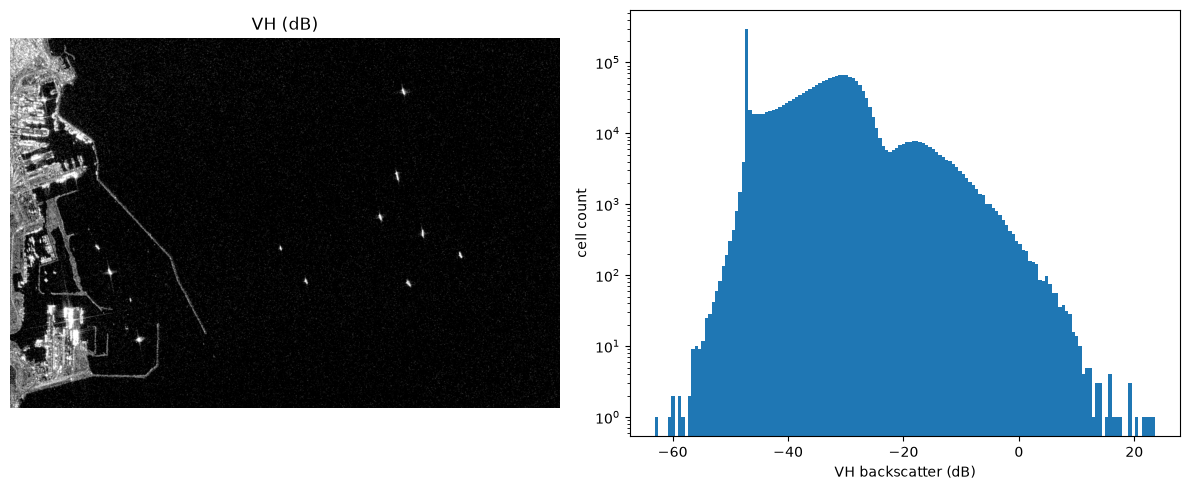

In [38]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.imshow(vh, cmap='gray', vmin=-30, vmax=-5)
ax1.set_title('VH (dB)')
ax1.axis('off')

ax2.hist(vh[~np.isnan(vh)].ravel(), bins=150)
ax2.set_yscale('log')
ax2.set_xlabel('VH backscatter (dB)')
ax2.set_ylabel('cell count')

plt.tight_layout()
plt.show()

In [43]:
# Threshold in dB (starting guess, tune by eye / histogram)
threshold = -8

vh = image.select('VH').clip(aoi)

# 1 where VH > threshold, masked (transparent) everywhere else
bright = vh.gt(threshold).selfMask()

Map.addLayer(vh, {'min': -30, 'max': -5}, 'VH (dB)')
Map.addLayer(bright, {'palette': ['red']}, f'VH > {threshold} dB')
Map.centerObject(aoi, 12)
Map

Map(bottom=381056.0, center=[44.130033974128644, 28.74500000000076], controls=(WidgetControl(options=['positio…

In [10]:
print(image.date().format('YYYY-MM-dd HH:mm').getInfo())

2019-10-01 15:59
